<a href="https://colab.research.google.com/github/snehag77/Recipe-Generator/blob/main/04_image_and_checks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#04_image_and_checks.ipynb

In [1]:
import os, json, re, sys
from google.colab import drive
drive.mount("/content/drive")

BASE = "/content/drive/MyDrive/P45_recipe_gen"
os.makedirs(f"{BASE}/outputs/images", exist_ok=True)
sys.path.append(BASE)
print(os.listdir(f"{BASE}/outputs"))

Mounted at /content/drive
['test_sets.json', 'base_outputs.json', 'base_metrics.json', 'gpt2_curves.png', 'finetuned_metrics.json', 'comparison_5sets.json', 'summary_metrics.csv', 'ner_history.json', 'ner_curves.png', 'ner_metrics.json', 'images']


In [2]:
%%writefile /content/drive/MyDrive/P45_recipe_gen/checks.py
import re

# ------------------------------------------------------------------
# Parsing the model output
# ------------------------------------------------------------------
def trim_output(text):
    i = text.find("<END_STEPS>")
    return text[: i + len("<END_STEPS>")] if i != -1 else text

def parse_output(text):
    def grab(start, end):
        m = re.search(rf"{re.escape(start)}(.*?){re.escape(end)}", text, re.S)
        return m.group(1).strip() if m else None
    return {"title": grab("<TITLE>", "<END_TITLE>"),
            "quantities": grab("<QUANTITIES>", "<END_QTY>"),
            "steps": grab("<STEPS>", "<END_STEPS>")}

# ------------------------------------------------------------------
# U5a: allergen detection (rule-based)
# ------------------------------------------------------------------
ALLERGENS = {
    "Milk": ["milk", "butter", "ghee", "cream", "cheese", "paneer", "curd", "yogurt", "yoghurt",
             "whey", "casein", "buttermilk", "khoa", "mawa", "mozzarella", "parmesan",
             "cheddar", "ricotta", "custard"],
    "Eggs": ["egg", "mayonnaise", "mayo", "meringue", "albumen"],
    "Peanuts": ["peanut", "groundnut"],
    "Tree nuts": ["almond", "walnut", "cashew", "pistachio", "pecan", "hazelnut", "macadamia",
                  "brazil nut", "pine nut", "marzipan", "praline"],
    "Wheat/Gluten": ["wheat", "flour", "maida", "atta", "semolina", "suji", "rava", "bread",
                     "bread crumb", "breadcrumb", "pasta", "spaghetti", "macaroni", "noodle",
                     "couscous", "barley", "rye", "seitan", "soy sauce", "tortilla", "cracker",
                     "biscuit", "roti", "naan", "chapati", "bulgur"],
    "Soy": ["soy", "soya", "soybean", "tofu", "edamame", "miso", "tempeh", "tamari"],
    "Fish": ["fish", "salmon", "tuna", "cod", "anchovy", "anchovies", "sardine", "mackerel",
             "trout", "tilapia", "pomfret", "hilsa", "worcestershire"],
    "Shellfish": ["shrimp", "prawn", "crab", "lobster", "crayfish", "oyster", "clam", "mussel",
                  "scallop", "squid", "octopus"],
    "Sesame": ["sesame", "tahini", "gingelly"],
}

# phrases that contain an allergen word but mean something else (or a different allergen)
SAFE_SWAPS = {
    "coconut milk": "coconut", "coconut cream": "coconut", "oat milk": "oat",
    "rice milk": "ricegrain", "soy milk": "soy", "almond milk": "almond", "cashew milk": "cashew",
    "peanut butter": "peanut", "almond butter": "almond", "cocoa butter": "cocoa",
    "shea butter": "shea", "cream of tartar": "tartar",
    "rice flour": "ricegrain", "corn flour": "corngrain", "cornflour": "corngrain",
    "almond flour": "almond", "coconut flour": "coconut", "gram flour": "besan",
    "chickpea flour": "besan", "buckwheat flour": "buckwheatgrain", "soy flour": "soy",
}

_ALLERGEN_RX = {
    name: re.compile(r"\b(?:" + "|".join(re.escape(k) for k in sorted(kws, key=len, reverse=True))
                     + r")(?:s|es)?\b")
    for name, kws in ALLERGENS.items()
}

def _neutralize(text):
    t = text.lower()
    for k in sorted(SAFE_SWAPS, key=len, reverse=True):
        t = t.replace(k, SAFE_SWAPS[k])
    return t

def detect_allergens(text):
    """Returns {allergen: [trigger words]} found in text."""
    t = _neutralize(text or "")
    found = {}
    for name, rx in _ALLERGEN_RX.items():
        hits = sorted({m.group(0) for m in rx.finditer(t)})
        if hits:
            found[name] = hits
    return found

def allergen_report(input_ings, recipe_text):
    declared = detect_allergens(", ".join(input_ings))
    in_recipe = detect_allergens(recipe_text)
    added = {k: v for k, v in in_recipe.items() if k not in declared}
    return {"in_recipe": in_recipe, "added_by_model": added}

def format_allergen_warning(report):
    rec, added = report["in_recipe"], report["added_by_model"]
    if not rec:
        return "No common allergens detected (informational only; always check labels)."
    parts = [f"{k} ({', '.join(v)})" for k, v in rec.items()]
    msg = "⚠️ Contains: " + "; ".join(parts) + "."
    if added:
        msg += " Not in your ingredient list, added by the model: " + ", ".join(added) + "."
    msg += " Informational only; may miss allergens or cross-contact. Always check labels."
    return msg

# ------------------------------------------------------------------
# U5b: impossible quantities
# ------------------------------------------------------------------
FRAC_CHARS = {"½": "1/2", "¼": "1/4", "¾": "3/4", "⅓": "1/3", "⅔": "2/3", "⅛": "1/8"}

# approximate grams or millilitres per unit (1 ml ~ 1 g, a rough assumption for sanity checks)
UNIT_TABLE = {
    "g": 1, "gram": 1, "grams": 1, "kg": 1000, "kilogram": 1000, "mg": 0.001,
    "oz": 28.35, "ounce": 28.35, "ounces": 28.35,
    "lb": 453.6, "lbs": 453.6, "pound": 453.6, "pounds": 453.6,
    "ml": 1, "l": 1000, "liter": 1000, "litre": 1000,
    "tsp": 5, "teaspoon": 5, "teaspoons": 5,
    "tbsp": 15, "tablespoon": 15, "tablespoons": 15,
    "c": 240, "cup": 240, "cups": 240, "pt": 473, "qt": 946,
    "pinch": 0.3, "dash": 0.6, "clove": 5, "cloves": 5,
    "can": 400, "cans": 400, "pkg": 250, "package": 250, "jar": 350,
    "stick": 113, "sticks": 113, "slice": 30, "slices": 30,
    "piece": 50, "pieces": 50, "bunch": 100,
}

# (name regex, max grams/ml for a whole recipe, label)
CATEGORY_LIMITS = [
    (r"\bsalt\b", 30, "salt"),
    (r"\b(?:baking powder|baking soda|yeast)\b", 30, "leavening"),
    (r"\b(?:vanilla|extract|essence)\b", 30, "extract"),
    (r"\b(?:black pepper|white pepper|cayenne|chili powder|chilli powder|paprika|cumin|turmeric|"
     r"cinnamon|garam masala|coriander powder|oregano|thyme|nutmeg|cloves)\b", 60, "spice"),
    (r"\b(?:sugar|jaggery|honey|syrup)\b", 800, "sweetener"),
    (r"\b(?:oil|butter|ghee|margarine)\b", 600, "fat"),
    (r"\b(?:flour|maida|atta|semolina|oats|rice)\b", 2500, "grain/flour"),
    (r"\b(?:milk|water|stock|broth|cream)\b", 4000, "liquid"),
    (r"\b(?:chicken|beef|pork|lamb|mutton|fish|paneer|tofu|meat)\b", 3000, "protein"),
]
GLOBAL_MAX = 5000
COUNT_LIMITS = [(r"\begg", 12), (r"\bonion", 10), (r"\btomato", 15), (r"\bpotato", 15),
                (r"\b(?:apple|banana|lemon|lime|orange)", 15), (r"\bgarlic", 20)]
DEFAULT_COUNT_LIMIT = 30
STAPLES = {"salt", "water", "oil", "pepper", "sugar", "butter", "flour", "vanilla", "baking", "ice"}
SKIP_AMOUNT = re.compile(r"to taste|as needed|for (?:serving|garnish|frying|greasing)|pinch|dash|optional", re.I)

_NUM, _FRAC = r"\d+(?:\.\d+)?", r"\d+/\d+"
AMOUNT_RE = re.compile(
    rf"^(?P<a>(?:{_NUM}\s+)?{_FRAC}|{_NUM})(?:\s*(?:-|–|to)\s*(?P<b>(?:{_NUM}\s+)?{_FRAC}|{_NUM}))?")

def _to_float(s):
    s = s.strip()
    if " " in s:
        whole, frac = s.split()
        f = _to_float(frac)
        return None if f is None else float(whole) + f
    if "/" in s:
        n, d = s.split("/")
        return None if float(d) == 0 else float(n) / float(d)
    return float(s)

def parse_quantity_line(line):
    s = line.strip()
    for k, v in FRAC_CHARS.items():
        s = s.replace(k, " " + v + " ")
    s = re.sub(r"\s*/\s*", "/", s)
    s = re.sub(r"\s+", " ", s).strip()
    out = {"raw": line.strip(), "amount": None, "unit": None, "base": None, "name": s,
           "negative": False, "bad_fraction": False, "no_amount": False}
    if not s:
        return None
    if re.match(r"^-\s*\d", s):
        out["negative"] = True
        s = s.lstrip("- ").strip()
    m = AMOUNT_RE.match(s)
    if not m:
        out["no_amount"] = True
        out["name"] = s
        return out
    a = _to_float(m["a"])
    b = _to_float(m["b"]) if m["b"] else None
    if a is None or (m["b"] and b is None):
        out["bad_fraction"] = True
        return out
    amount = max(a, b) if b is not None else a
    rest = s[m.end():].strip()
    out["amount"] = amount

    # "1 (8 oz.) pkg. cream cheese": size in parentheses times count
    pm = re.match(r"\((\d+(?:\.\d+)?)\s*([a-zA-Z]+)\.?\)\s*(.*)", rest)
    if pm and pm[2].lower() in UNIT_TABLE:
        out["unit"] = pm[2].lower()
        out["base"] = amount * float(pm[1]) * UNIT_TABLE[pm[2].lower()]
        rest = pm[3]
        um = re.match(r"([a-zA-Z]+)\.?\s*(.*)", rest)       # drop container word (pkg, can)
        if um and um[1].lower() in UNIT_TABLE:
            rest = um[2]
    else:
        um = re.match(r"([a-zA-Z]+)\.?\s*(.*)", rest)
        if um and um[1].lower() in UNIT_TABLE:
            out["unit"] = um[1].lower()
            out["base"] = amount * UNIT_TABLE[um[1].lower()]
            rest = um[2]
    rest = re.sub(r"^of\s+", "", rest)
    out["name"] = rest.split(",")[0].strip()
    return out

def _stem(w):
    return w[:-1] if w.endswith("s") else w

def check_quantities(qty_text, input_ings=None):
    flags = []
    lines = [l for l in re.split(r"[;\n]", qty_text or "") if l.strip()]
    if not lines:
        return [("error", "No quantities found in the recipe.")]
    input_tokens = {_stem(t) for i in (input_ings or []) for t in re.findall(r"[a-z]+", i.lower())}
    for line in lines:
        q = parse_quantity_line(line)
        if q is None:
            continue
        name, name_l = q["name"] or q["raw"], (q["name"] or "").lower()
        if q["negative"]:
            flags.append(("error", f"'{q['raw']}': negative amount."))
            continue
        if q["bad_fraction"]:
            flags.append(("error", f"'{q['raw']}': impossible fraction (division by zero)."))
            continue
        if q["no_amount"]:
            if not SKIP_AMOUNT.search(q["raw"]):
                flags.append(("warn", f"'{q['raw']}': no amount given."))
            continue
        amt = q["amount"]
        if amt == 0:
            flags.append(("error", f"'{q['raw']}': zero amount."))
            continue
        if q["unit"] is None:                                     # count items, e.g. "3 eggs"
            limit = next((lim for pat, lim in COUNT_LIMITS if re.search(pat, name_l)), DEFAULT_COUNT_LIMIT)
            if amt > limit:
                level = "error" if amt > 3 * limit else "warn"
                flags.append((level, f"'{q['raw']}': {amt:g} {name} looks unrealistic or the unit is missing."))
        else:
            base = q["base"]
            if base > GLOBAL_MAX:
                flags.append(("error", f"'{q['raw']}': over {GLOBAL_MAX/1000:g} kg/L for one ingredient."))
            else:
                for pat, lim, label in CATEGORY_LIMITS:
                    if re.search(pat, name_l):
                        if base > lim:
                            flags.append(("error", f"'{q['raw']}': about {base:g} g/ml of {label}, "
                                                   f"more than a sane limit (~{lim} g/ml)."))
                        break
        # ingredient that the user never listed (soft note)
        if input_ings and name_l and not any(s in name_l for s in STAPLES):
            toks = {_stem(t) for t in re.findall(r"[a-z]+", name_l)}
            if not toks & input_tokens:
                flags.append(("info", f"'{name}' was added by the model (not in your ingredient list)."))
    return flags

# ------------------------------------------------------------------
# U5b: impossible times and temperatures in the steps
# ------------------------------------------------------------------
TIME_RE = re.compile(r"(\d+(?:\.\d+)?)\s*(seconds?|secs?|minutes?|mins?|hours?|hrs?|days?)\b", re.I)
TEMP_RE = re.compile(r"(\d{2,4})\s*(?:°\s*|degrees?\s*)([FC])\b", re.I)
SLOW_CTX = re.compile(r"marinat|chill|refrigerat|soak|ferment|rise|proof|freez|overnight|rest", re.I)

def check_steps(steps_text):
    flags = []
    t = steps_text or ""
    for m in TIME_RE.finditer(t):
        v, u = float(m[1]), m[2].lower()
        mins = v / 60 if u.startswith("sec") else v if u.startswith("min") else v * 60 if u.startswith(("h")) else v * 1440
        slow = bool(SLOW_CTX.search(t[max(0, m.start() - 60): m.start()]))
        limit = 4320 if slow else 480
        if mins > limit:
            flags.append(("error", f"Time '{m[0]}' looks unrealistic for this step."))
    for m in TEMP_RE.finditer(t):
        v, u = int(m[1]), m[2].upper()
        if (u == "F" and v > 600) or (u == "C" and v > 320):
            flags.append(("error", f"Temperature '{m[0]}' is unrealistically high for a home oven."))
    return flags

def validate_recipe(parsed, input_ings=None):
    flags = []
    for key in ("title", "quantities", "steps"):
        if not parsed.get(key):
            flags.append(("warn", f"Recipe is incomplete: missing {key}."))
    flags += check_quantities(parsed.get("quantities"), input_ings)
    flags += check_steps(parsed.get("steps"))
    return flags

ICONS = {"error": "🚩", "warn": "⚠️", "info": "ℹ️"}
def format_flags(flags):
    return "\n".join(f"{ICONS[l]} {m}" for l, m in flags) if flags else "✅ No quantity problems found."

Writing /content/drive/MyDrive/P45_recipe_gen/checks.py


In [3]:
import importlib, checks
importlib.reload(checks)
from checks import *

print(detect_allergens("2 cups flour, 3 eggs, 1 tbsp butter, 1 cup coconut milk, peanut butter"))
# expect: Milk (butter), Eggs (eggs), Wheat/Gluten (flour), Peanuts (peanut)
# NOT milk from coconut milk, NOT milk from peanut butter's "butter"

for text in ["soy sauce and sesame oil", "eggplant curry with almond flour", "cream of tartar and cocoa butter",
             "prawn fried rice with soy sauce"]:
    print(text, "->", detect_allergens(text))

{'Milk': ['butter'], 'Eggs': ['eggs'], 'Peanuts': ['peanut'], 'Wheat/Gluten': ['flour']}
soy sauce and sesame oil -> {'Wheat/Gluten': ['soy sauce'], 'Soy': ['soy'], 'Sesame': ['sesame']}
eggplant curry with almond flour -> {'Tree nuts': ['almond']}
cream of tartar and cocoa butter -> {}
prawn fried rice with soy sauce -> {'Wheat/Gluten': ['soy sauce'], 'Soy': ['soy'], 'Shellfish': ['prawn']}


In [4]:
cases = {
    "good":            ("2 cups flour; 1 tsp salt; 3 eggs; 1 1/2 tbsp sugar", "Bake at 350 degrees F for 25 minutes."),
    "huge salt":       ("500 cups salt; 2 eggs", "Mix well."),
    "300 g salt":      ("300 g salt; 1 cup rice", "Cook for 20 minutes."),
    "zero amount":     ("0 eggs; 1 cup milk", "Whisk."),
    "negative":        ("-2 tbsp sugar", "Stir."),
    "divide by zero":  ("1/0 cup flour", "Stir."),
    "missing unit":    ("250 flour; 1 tsp salt", "Mix."),
    "40 eggs":         ("40 eggs; 1 cup sugar", "Beat."),
    "10 kg butter":    ("10 kg butter", "Melt."),
    "absurd time":     ("1 cup rice", "Bake for 90 hours at 900 degrees F."),
    "ok marinade":     ("500 g chicken; 2 tbsp soy sauce", "Marinate for 24 hours in the refrigerator, then cook 20 minutes."),
    "range + parens":  ("1 (8 oz.) pkg. cream cheese; 2-3 tbsp honey", "Chill 1 hour."),
}
for name, (q, s) in cases.items():
    flags = validate_recipe({"title": "x", "quantities": q, "steps": s})
    print(f"--- {name}\n{format_flags(flags)}")

--- good
✅ No quantity problems found.
--- huge salt
🚩 '500 cups salt': over 5 kg/L for one ingredient.
--- 300 g salt
🚩 '300 g salt': about 300 g/ml of salt, more than a sane limit (~30 g/ml).
--- zero amount
🚩 '0 eggs': zero amount.
--- negative
🚩 '-2 tbsp sugar': negative amount.
--- divide by zero
🚩 '1/0 cup flour': impossible fraction (division by zero).
--- missing unit
🚩 '250 flour': 250 flour looks unrealistic or the unit is missing.
--- 40 eggs
🚩 '40 eggs': 40 eggs looks unrealistic or the unit is missing.
--- 10 kg butter
🚩 '10 kg butter': over 5 kg/L for one ingredient.
--- absurd time
🚩 Time '90 hours' looks unrealistic for this step.
🚩 Temperature '900 degrees F' is unrealistically high for a home oven.
--- ok marinade
✅ No quantity problems found.
--- range + parens
✅ No quantity problems found.


In [5]:
TEST_SETS = json.load(open(f"{BASE}/outputs/test_sets.json"))
comp = json.load(open(f"{BASE}/outputs/comparison_5sets.json"))

records = []
for ings, row in zip(TEST_SETS, comp):
    text = trim_output(row["finetuned_output"])
    parsed = parse_output(text)
    records.append({"ingredients": ings, "text": text, "parsed": parsed})

for r in records:
    print("=" * 70); print(r["ingredients"]); print(r["parsed"])

['chicken', 'rice', 'garlic', 'soy sauce']
{'title': 'Honey Dukes', 'quantities': '1 can chicken wings; 1 can rice; 1 can soy sauce; 1/2 c. garlic', 'steps': '1. Place in a baking dish to be coated with a little water. 2. Bake at 375° for about 10 to 15 minutes. 3. When brown, remove from oven and let cool slightly.'}
['paneer', 'tomato', 'onion', 'cream', 'garam masala']
{'title': 'Barbecue Sauce', 'quantities': '1 can cream (not instant); 1/4 c. barbecue sauce; 1 onion, diced; 1 Tbsp. garam masala; 1 pkg. Tabasco dry mustard mix; 2 pkg. Velveeta or black pepper', 'steps': '1. Mix all ingredients well. 2. Serve with barbecue sauce. 3. Yields 8 servings.'}
['flour', 'butter', 'sugar', 'eggs', 'vanilla']
{'title': 'Flour Cookies', 'quantities': '2 c. flour; 1 stick butter; 1/2 tsp. vanilla; 1/2 c. sugar; 2 eggs', 'steps': '1. Mix dry ingredients and vanilla. 2. Combine eggs and butter. 3. Add flour mixture and sugar. 4. Beat until well blended. 5. Add flour mixture and let stand 3 minut

In [6]:
for r in records:
    p = r["parsed"]
    recipe_text = " ".join(filter(None, [p["title"], p["quantities"], p["steps"]]))
    r["allergens"] = allergen_report(r["ingredients"], recipe_text)
    r["flags"] = validate_recipe(p, r["ingredients"])
    print("=" * 70)
    print("INPUT:", r["ingredients"])
    print(format_allergen_warning(r["allergens"]))
    print(format_flags(r["flags"]))

INPUT: ['chicken', 'rice', 'garlic', 'soy sauce']
⚠️ Contains: Wheat/Gluten (soy sauce); Soy (soy). Informational only; may miss allergens or cross-contact. Always check labels.
✅ No quantity problems found.
INPUT: ['paneer', 'tomato', 'onion', 'cream', 'garam masala']
⚠️ Contains: Milk (cream). Informational only; may miss allergens or cross-contact. Always check labels.
ℹ️ 'barbecue sauce' was added by the model (not in your ingredient list).
ℹ️ 'Tabasco dry mustard mix' was added by the model (not in your ingredient list).
🚩 '2 pkg. Velveeta or black pepper': about 500 g/ml of spice, more than a sane limit (~60 g/ml).
INPUT: ['flour', 'butter', 'sugar', 'eggs', 'vanilla']
⚠️ Contains: Milk (butter); Eggs (eggs); Wheat/Gluten (flour). Informational only; may miss allergens or cross-contact. Always check labels.
✅ No quantity problems found.
INPUT: ['potato', 'spinach', 'chickpeas', 'cumin']
⚠️ Contains: Milk (cheese, parmesan); Wheat/Gluten (spaghetti). Not in your ingredient list, a

In [7]:
!pip install -q keras-cv
import os
os.environ["KERAS_BACKEND"] = "tensorflow"
import keras, keras_cv
keras.mixed_precision.set_global_policy("mixed_float16")

sd = keras_cv.models.StableDiffusion(img_width=512, img_height=512, jit_compile=False)

NEG = "text, watermark, logo, blurry, deformed, people, hands, cartoon, low quality"

def generate_image(prompt, seed=42):
    imgs = sd.text_to_image(prompt, negative_prompt=NEG, batch_size=1, num_steps=25,
                            unconditional_guidance_scale=7.5, seed=seed)
    return imgs[0]          # numpy uint8 array (512, 512, 3)

By using this model checkpoint, you acknowledge that its usage is subject to the terms of the CreativeML Open RAIL-M license at https://raw.githubusercontent.com/CompVis/stable-diffusion/main/LICENSE


In [9]:
!pip install -q diffusers accelerate safetensors transformers
import torch
from diffusers import AutoPipelineForText2Image

pipe = AutoPipelineForText2Image.from_pretrained(
    "stabilityai/sdxl-turbo", torch_dtype=torch.float16, variant="fp16").to("cuda")

NEG = "text, watermark, logo, blurry, deformed, people, hands, cartoon, low quality"

def generate_image(prompt, seed=42):
    g = torch.Generator("cuda").manual_seed(seed)
    img = pipe(prompt, negative_prompt=NEG, num_inference_steps=4, guidance_scale=0.0,
               width=512, height=512, generator=g).images[0]
    return np.array(img)

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/diffusers/pipelines/stable_diffusion_xl/pipeline_stable_diffusion_xl.py:750: FutureWarning: `upcast_vae` is deprecated and will be removed in version 1.0.0. `upcast_vae` is deprecated. Please use `pipe.vae.to(torch.float32)`. For more details, please refer to: https://github.com/huggingface/diffusers/pull/12619#issue-3606633695.
  deprecate(
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  0%|          | 0/4 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  0%|          | 0/4 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  0%|          | 0/4 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  0%|          | 0/4 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


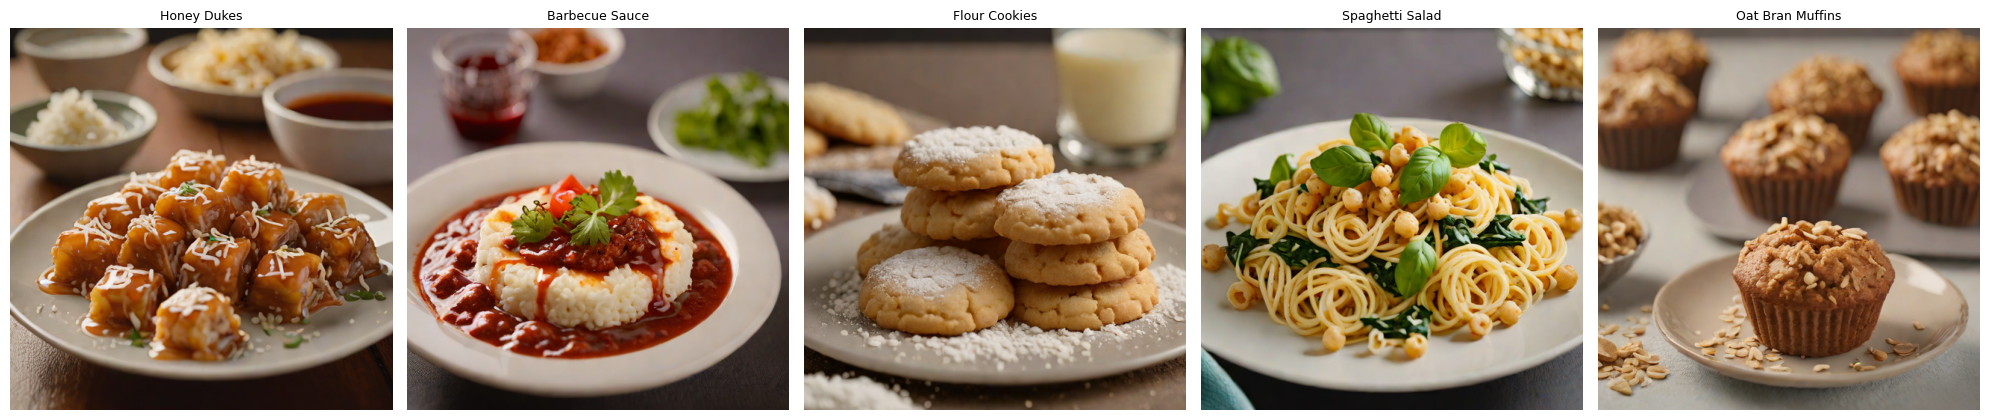

In [10]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

def build_image_prompt(title, ingredients):
    dish = title if title else "a home-cooked dish"
    main = ", ".join(ingredients[:4])
    return (f"professional food photography of {dish}, made with {main}, "
            f"plated on a ceramic dish, natural window light, shallow depth of field, high detail")

fig, axes = plt.subplots(1, len(records), figsize=(4 * len(records), 4.5))
for i, r in enumerate(records):
    prompt = build_image_prompt(r["parsed"]["title"], r["ingredients"])
    img = generate_image(prompt, seed=42 + i)
    path = f"{BASE}/outputs/images/dish_{i+1}.png"
    Image.fromarray(img).save(path)
    r["image_prompt"], r["image_path"] = prompt, path
    axes[i].imshow(img); axes[i].axis("off")
    axes[i].set_title((r["parsed"]["title"] or "no title")[:30], fontsize=9)
plt.tight_layout()
plt.savefig(f"{BASE}/outputs/image_grid.png", dpi=150); plt.show()

In [11]:
out = [{"ingredients": r["ingredients"], "title": r["parsed"]["title"],
        "quantities": r["parsed"]["quantities"], "steps": r["parsed"]["steps"],
        "allergens": r["allergens"], "flags": r["flags"],
        "image_prompt": r["image_prompt"], "image_path": r["image_path"]} for r in records]
json.dump(out, open(f"{BASE}/outputs/pipeline_results.json", "w"), indent=2)
print("saved", len(out), "results")

saved 5 results
